# Practical 22: Polynomial Regression – Car Price Prediction

**Aim:** To predict car prices using year and kilometres driven with Polynomial Regression and visualize the regression curve.

**Dataset:** Car Details from Car Dekho (Kaggle)

**Kaggle link:** https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho

### Dataset setup
1. Download and extract the Kaggle dataset.
2. Open the folder and locate `car details v3.csv` or the matching CSV file.
3. Keep the CSV file in the same folder as this notebook.
4. Run each cell using **Shift + Enter**.

**Columns used:** `year`, `km_driven`, `selling_price`.

**Reference style:** This follows the uploaded Polynomial Regression notebook style: load data, check missing values, select X and y, split data, create a Polynomial Regression model, check R² scores and plot the curve.

## 1. Import libraries

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures


## 2. Load the dataset

In [42]:
df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")
df.head()


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Display the dataset

In [43]:
df.shape


(4340, 8)

In [44]:
df.isna().sum()


name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

## 4. Select input and output

In [45]:
# Select input and output
X = df[["year", "km_driven"]]
y = df["selling_price"]

# Remove missing values
data = pd.concat([X, y], axis=1).dropna()
X = data[["year", "km_driven"]]
y = data["selling_price"]

X.head()


,year,km_driven
0,2007,70000
1,2007,50000
2,2012,100000
3,2017,46000
4,2014,141000


In [46]:
y.head()


0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64

## 5. Split the data

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)


## 6. Create Polynomial Regression model

In [48]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)


LinearRegression()

## 7. Predict car price

In [49]:
# Example: year = 2014 and km_driven = 141000
ip = pd.DataFrame([[2014, 141000]], columns=["year", "km_driven"])

ip_poly = poly.transform(ip)
model.predict(ip_poly)


array([484897.0323588])

## 8. Check model accuracy

In [50]:
print("Training R2:", model.score(X_train_poly, y_train))
print("Testing R2:", model.score(X_test_poly, y_test))


Training R2: 0.17694413922741892
Testing R2: 0.17159568944457848


## 9. Visualize the Polynomial Regression curve

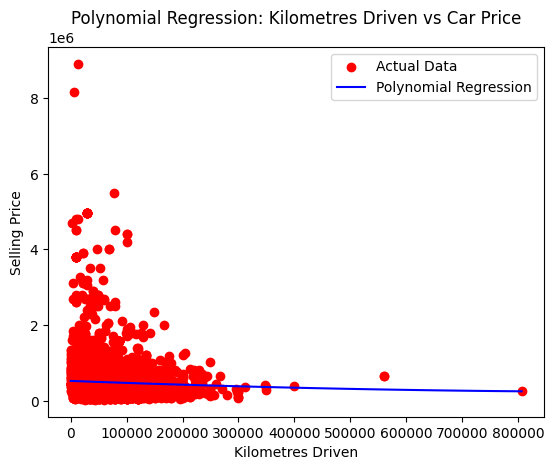

In [51]:
# Keep year fixed at its average value
year_value = X["year"].mean()

# Create km_driven values for the curve
km_values = np.linspace(X["km_driven"].min(), X["km_driven"].max(), 100)

X_plot = pd.DataFrame({
    "year": year_value,
    "km_driven": km_values
})

X_plot_poly = poly.transform(X_plot)
y_plot = model.predict(X_plot_poly)

plt.scatter(X["km_driven"], y, color="red", label="Actual Data")
plt.plot(km_values, y_plot, color="blue", label="Polynomial Regression")

plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")
plt.title("Polynomial Regression: Kilometres Driven vs Car Price")
plt.legend()
plt.show()


## Conclusion

Thus, Polynomial Regression was implemented to predict car prices using `year` and `km_driven`. The model was trained using `fit()` and car prices were predicted using `predict()`. The graph shows the polynomial regression curve while keeping the year fixed at its average value.